# Fig. 5 Supplementary Figure 1 panels b-h

This notebook redraws SFig1 panels b-h only. Panel a is intentionally omitted. Each plotted panel is generated in its own cell, and the reproducible data bundle is stored under `data/sfig1`.


In [1]:
import omicverse as ov
import scanpy as sc
import matplotlib.pyplot as plt
ov.plot_set(font_path='Arial')
sc.settings.set_figure_params(dpi=300, vector_friendly=True)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 18,
    'axes.labelsize': 18,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 18,
    'axes.linewidth': 1.8,
    'xtick.major.width': 1.6,
    'ytick.major.width': 1.6,
})


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.1.0)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/anndata/__init__.py:70: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)


🔬 Starting plot initialization...
Using already downloaded Arial font from: /tmp/omicverse_arial.ttf


Registered as: Arial
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 8
    • [CUDA 0] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 1] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 2] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 3] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 4] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 5] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 6] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 7] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                           

In [2]:
from pathlib import Path
import hashlib
import importlib.util
import json
import sys

import fitz
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import numpy as np
import pandas as pd
from IPython.display import Image as IPyImage, display
from PIL import Image

ROOT = Path('.').resolve()
DATA = ROOT / 'data' / 'sfig1'
SCRIPT_DIR = ROOT / 'scripts' / 'sfig1'
OUT = ROOT / 'outputs'
PANEL_DIR = OUT / 'sfig1_panels'
TABLE_DIR = OUT / 'sfig1_tables'
INTERMEDIATE_DIR = OUT / 'sfig1_intermediate'
MANIFEST = ROOT / 'MANIFEST_sfig1.json'
for path in [PANEL_DIR, TABLE_DIR, INTERMEDIATE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

def require_path(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    return path

def import_module_from_path(name, path):
    spec = importlib.util.spec_from_file_location(name, str(require_path(path)))
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

def display_pdf_page(pdf_path, zoom=1.55):
    doc = fitz.open(str(require_path(pdf_path)))
    pix = doc[0].get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False)
    display(IPyImage(data=pix.tobytes('png')))

def save_and_display(fig, stem, zoom=1.55, tight=True):
    pdf = PANEL_DIR / f'{stem}.pdf'
    png = PANEL_DIR / f'{stem}.png'
    kwargs = {'bbox_inches': 'tight', 'pad_inches': 0.03} if tight else {}
    fig.savefig(pdf, dpi=300, **kwargs)
    fig.savefig(png, dpi=300, **kwargs)
    plt.close(fig)
    print(f'saved: {pdf}')
    print(f'saved: {png}')
    display_pdf_page(pdf, zoom=zoom)

def clean_image_axis(ax, frame=True):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(frame)
        spine.set_linewidth(1.8)
        spine.set_edgecolor('black')

def clean_xy_axis(ax):
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.8)
    ax.spines['bottom'].set_linewidth(1.8)
    ax.tick_params(width=1.6, length=6)

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def refresh_manifest():
    records = []
    for base in [DATA, SCRIPT_DIR, PANEL_DIR, TABLE_DIR, INTERMEDIATE_DIR]:
        for path in sorted(base.rglob('*')):
            if path.is_file():
                records.append({
                    'path': str(path.relative_to(ROOT)),
                    'size_bytes': path.stat().st_size,
                    'sha256': sha256_file(path),
                })
    payload = {
        'name': 'fig5_supplementary_1_reproduce',
        'panel_a': 'omitted by request',
        'panel_mapping': {
            'b': 'SkillOpt score trace',
            'c': 'SkillOpt edit history and validation matrix',
            'd': 'H&E overview with representative D0-D5 source boxes',
            'e': 'Representative D0-D5 context and zoomed morphology regions',
            'f': 'IGNITE tumor annotation benchmark overlay',
            'g': 'IGNITE tile-level AUROC',
            'h': 'IGNITE tile-level confusion matrix',
        },
        'files': records,
    }
    MANIFEST.write_text(json.dumps(payload, indent=2), encoding='utf-8')
    return pd.DataFrame(records)

skill = import_module_from_path('skill_iter_repro', SCRIPT_DIR / 'build_skill_iteration_validation_supplement.py')
ignite = import_module_from_path('ignite_repro', SCRIPT_DIR / 'build_ignite_single_roi_benchmark.py')


In [3]:
# Validate and summarize the reproducible bundle copied by the build script.
required = [
    DATA / 'skill_iteration' / 'tables' / 'lazyslide_skill_iteration_trace.csv',
    DATA / 'skill_iteration' / 'tables' / 'lazyslide_skill_edit_history.csv',
    DATA / 'skill_iteration' / 'tables' / 'lazyslide_skill_final_validation_report.csv',
    DATA / 'skill_iteration' / 'tables' / 'lazyslide_skill_evidence_sources.csv',
    DATA / 'he_roi_sources' / 'analysis_final_plotting_data' / 'visium_hd_he_thumbnail_stride32.npy',
    DATA / 'he_roi_sources' / 'analysis_final_plotting_data' / 'visium_hd_he_page_info.json',
    DATA / 'he_roi_sources' / 'tables' / 'supp_fig1_representative_roi_sources.csv',
    DATA / 'ignite_single_roi' / 'tables' / 'ignite_single_roi_tile_calls.csv',
    DATA / 'ignite_single_roi' / 'tables' / 'ignite_single_roi_tile_roc_curve.csv',
    DATA / 'ignite_single_roi' / 'tables' / 'ignite_single_roi_benchmark_metrics.csv',
]
for path in required:
    require_path(path)
bundle_summary = pd.DataFrame({
    'component': ['skill_iteration', 'he_roi_sources', 'ignite_single_roi'],
    'n_files': [
        sum(1 for p in (DATA / 'skill_iteration').rglob('*') if p.is_file()),
        sum(1 for p in (DATA / 'he_roi_sources').rglob('*') if p.is_file()),
        sum(1 for p in (DATA / 'ignite_single_roi').rglob('*') if p.is_file()),
    ],
})
display(bundle_summary)


           component  n_files
0    skill_iteration       13
1     he_roi_sources       22
2  ignite_single_roi       13

## Panel b


saved: ./outputs/sfig1_panels/sfig1_B_skillopt_score_trace.pdf
saved: ./outputs/sfig1_panels/sfig1_B_skillopt_score_trace.png


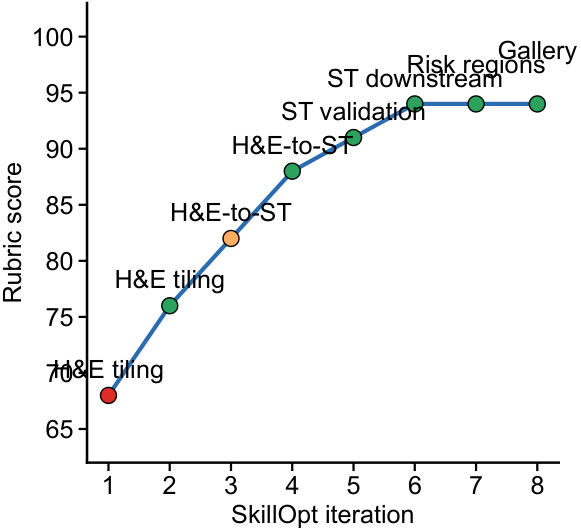

In [4]:
trace = pd.read_csv(DATA / 'skill_iteration' / 'tables' / 'lazyslide_skill_iteration_trace.csv')
fig, ax = plt.subplots(figsize=(6, 6))
skill.plot_score_trace(ax, trace)
save_and_display(fig, 'sfig1_B_skillopt_score_trace', zoom=1.4)


## Panel c


saved: ./outputs/sfig1_panels/sfig1_C_skillopt_edit_history_validation_matrix.pdf
saved: ./outputs/sfig1_panels/sfig1_C_skillopt_edit_history_validation_matrix.png


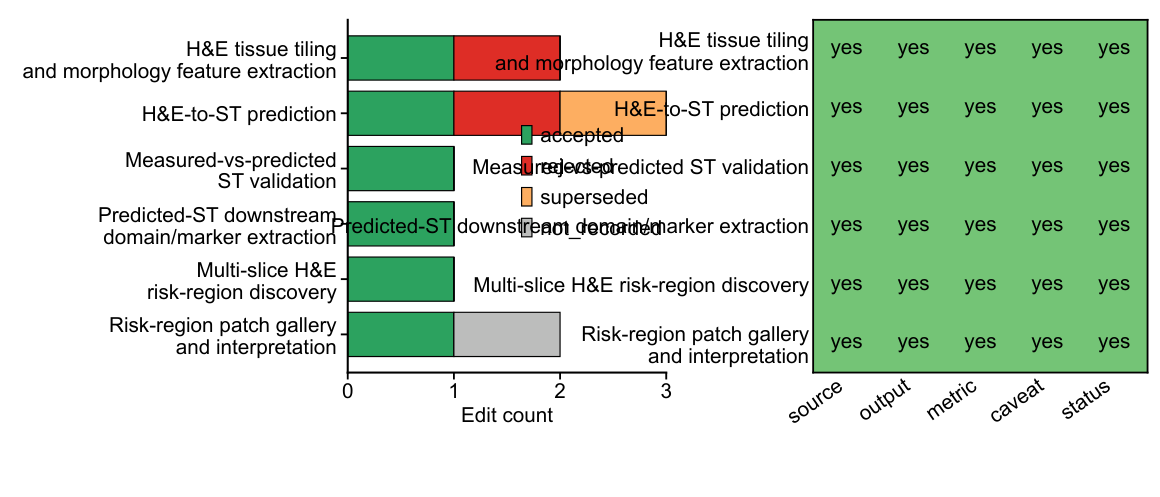

In [5]:
history = pd.read_csv(DATA / 'skill_iteration' / 'tables' / 'lazyslide_skill_edit_history.csv')
report = pd.read_csv(DATA / 'skill_iteration' / 'tables' / 'lazyslide_skill_final_validation_report.csv')
sources = pd.read_csv(DATA / 'skill_iteration' / 'tables' / 'lazyslide_skill_evidence_sources.csv')
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1.0, 1.05]})
skill.plot_edit_history(axes[0], history)
axes[0].set_yticklabels([
    'H&E tissue tiling' + chr(10) + 'and morphology feature extraction',
    'H&E-to-ST prediction',
    'Measured-vs-predicted' + chr(10) + 'ST validation',
    'Predicted-ST downstream' + chr(10) + 'domain/marker extraction',
    'Multi-slice H&E' + chr(10) + 'risk-region discovery',
    'Risk-region patch gallery' + chr(10) + 'and interpretation',
])
skill.plot_validation_matrix(axes[1], report, sources)
fig.subplots_adjust(left=0.30, right=0.99, bottom=0.25, top=0.96, wspace=0.45)
save_and_display(fig, 'sfig1_C_skillopt_edit_history_validation_matrix', zoom=1.15, tight=False)


## Panel d


saved: ./outputs/sfig1_panels/sfig1_D_he_overview_representative_features.pdf
saved: ./outputs/sfig1_panels/sfig1_D_he_overview_representative_features.png


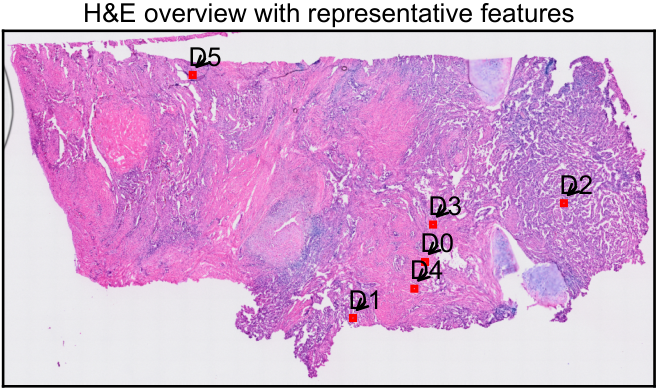

In [6]:
he_data = DATA / 'he_roi_sources' / 'analysis_final_plotting_data'
thumb = np.load(require_path(he_data / 'visium_hd_he_thumbnail_stride32.npy'))
page = json.loads(require_path(he_data / 'visium_hd_he_page_info.json').read_text())
roi = pd.read_csv(DATA / 'he_roi_sources' / 'tables' / 'supp_fig1_representative_roi_sources.csv')
crop_size = int(roi['crop_size_px'].iloc[0])

fig, ax = plt.subplots(figsize=(8, 5.4))
ax.imshow(thumb, extent=(0, page['width'], page['height'], 0))
for _, row in roi.sort_values('smoothed_domain').iterrows():
    ax.add_patch(mpatches.Rectangle(
        (row['center_x'] - crop_size / 2, row['center_y'] - crop_size / 2),
        crop_size,
        crop_size,
        fill=False,
        edgecolor='red',
        linewidth=2.4,
        zorder=20,
    ))
    ax.annotate(
        row['domain_label'],
        xy=(row['overview_arrow_target_x'], row['overview_arrow_target_y']),
        xytext=(row['overview_label_x'], row['overview_label_y']),
        color='black',
        ha='left',
        va='bottom',
        fontweight='bold',
        arrowprops={'arrowstyle': '->', 'color': 'black', 'lw': 1.8, 'shrinkA': 24, 'shrinkB': 4},
        zorder=30,
    )
ax.set_title('H&E overview with representative features')
clean_image_axis(ax, frame=True)
save_and_display(fig, 'sfig1_D_he_overview_representative_features', zoom=1.45)


## Panel e


saved: ./outputs/sfig1_panels/sfig1_E_representative_roi_contexts.pdf
saved: ./outputs/sfig1_panels/sfig1_E_representative_roi_contexts.png


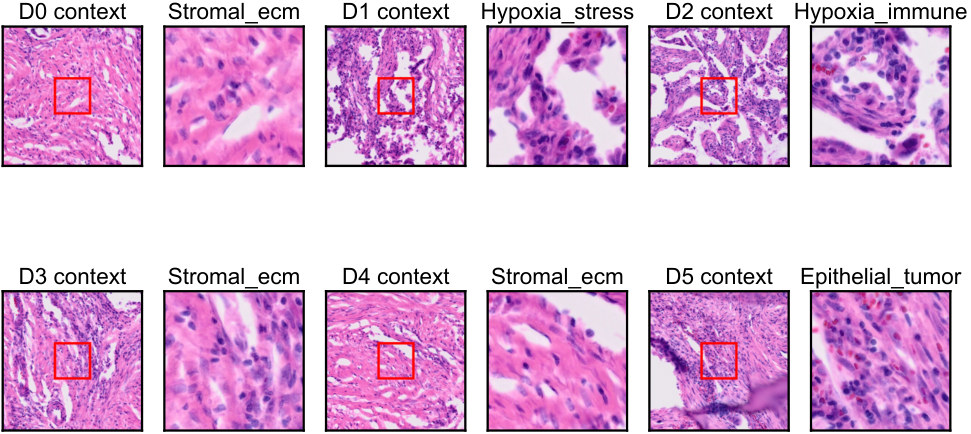

In [7]:
label_table = pd.read_csv(TABLE_DIR / 'supp_fig1_roi_panel_display_labels.csv')
roi = pd.read_csv(DATA / 'he_roi_sources' / 'tables' / 'supp_fig1_representative_roi_sources.csv')
roi = roi.merge(label_table[['domain_label', 'display_marker_label']], on='domain_label', how='left')
roi = roi.sort_values('smoothed_domain')
context_dir = DATA / 'he_roi_sources' / 'roi_context'
crop_dir = DATA / 'he_roi_sources' / 'analysis_final_plotting_data' / 'representative_tiles'

fig = plt.figure(figsize=(13.5, 6.8))
gs = fig.add_gridspec(2, 6, hspace=0.32, wspace=0.16)
for i, (_, row) in enumerate(roi.iterrows()):
    ax = fig.add_subplot(gs[i // 3, (i % 3) * 2])
    ax.imshow(Image.open(require_path(context_dir / row['context_file'])))
    ax.set_title(f"{row['domain_label']} context")
    clean_image_axis(ax, frame=True)

    ax = fig.add_subplot(gs[i // 3, (i % 3) * 2 + 1])
    ax.imshow(Image.open(require_path(crop_dir / row['crop_file'])))
    ax.set_title(str(row['display_marker_label']))
    clean_image_axis(ax, frame=True)
save_and_display(fig, 'sfig1_E_representative_roi_contexts', zoom=1.25)


## Panel f


saved: ./outputs/sfig1_panels/sfig1_F_ignite_tumor_overlay.pdf
saved: ./outputs/sfig1_panels/sfig1_F_ignite_tumor_overlay.png


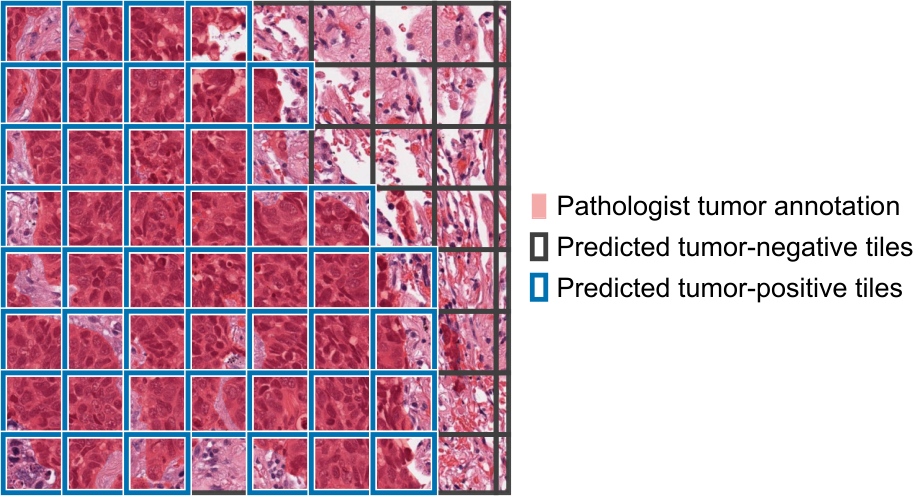

In [8]:
image = np.array(Image.open(require_path(DATA / 'ignite_single_roi' / 'inputs' / 'patient22_he_roi1_with_context_image.png')).convert('RGB'))
gt = np.array(Image.open(require_path(DATA / 'ignite_single_roi' / 'inputs' / 'patient22_he_roi1_with_context_annotation.png')))
pred = np.array(Image.open(require_path(DATA / 'ignite_single_roi' / 'inputs' / 'patient22_he_roi1_with_context_prediction.png')))
image, gt, pred, roi_extent = ignite.crop_to_annotation_roi(image, gt, pred)
tiles = pd.read_csv(DATA / 'ignite_single_roi' / 'tables' / 'ignite_single_roi_tile_calls.csv')

fig, ax = plt.subplots(figsize=(6, 6))
ignite.plot_overlay(ax, image, gt, tiles)
save_and_display(fig, 'sfig1_F_ignite_tumor_overlay', zoom=1.5)


## Panel g


saved: ./outputs/sfig1_panels/sfig1_G_ignite_tile_auroc.pdf
saved: ./outputs/sfig1_panels/sfig1_G_ignite_tile_auroc.png


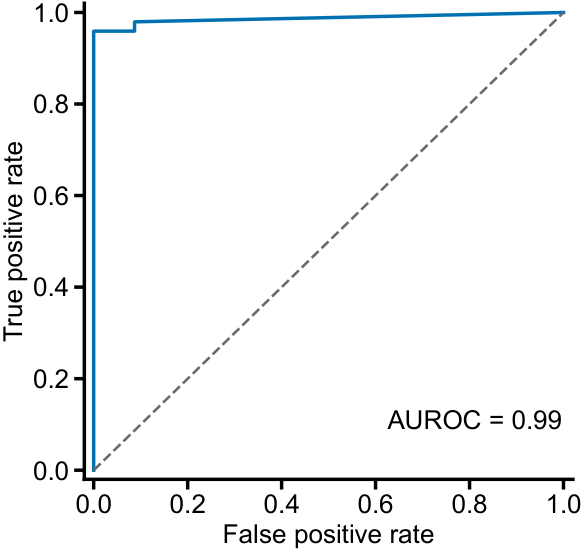

In [9]:
roc_df = pd.read_csv(DATA / 'ignite_single_roi' / 'tables' / 'ignite_single_roi_tile_roc_curve.csv')
metrics = pd.read_csv(DATA / 'ignite_single_roi' / 'tables' / 'ignite_single_roi_benchmark_metrics.csv')
fig, ax = plt.subplots(figsize=(6, 6))
ignite.plot_tile_auroc(ax, roc_df, metrics)
save_and_display(fig, 'sfig1_G_ignite_tile_auroc', zoom=1.45)


## Panel h


saved: ./outputs/sfig1_panels/sfig1_H_ignite_confusion_metrics.pdf
saved: ./outputs/sfig1_panels/sfig1_H_ignite_confusion_metrics.png


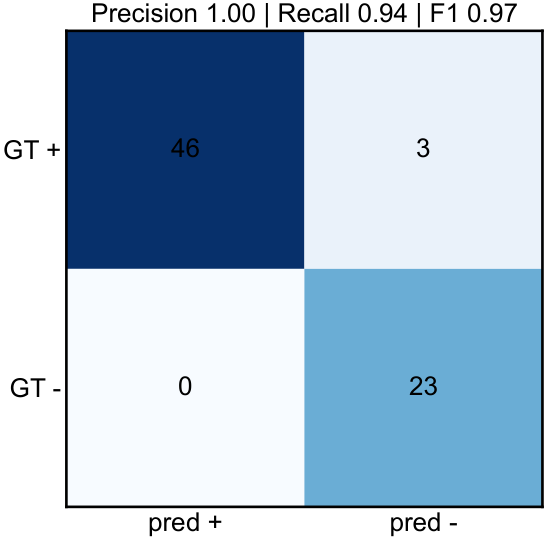

In [10]:
tiles = pd.read_csv(DATA / 'ignite_single_roi' / 'tables' / 'ignite_single_roi_tile_calls.csv')
metrics = pd.read_csv(DATA / 'ignite_single_roi' / 'tables' / 'ignite_single_roi_benchmark_metrics.csv')
fig, ax = plt.subplots(figsize=(6, 6))
ignite.plot_confusion_metrics(ax, metrics, tiles)
save_and_display(fig, 'sfig1_H_ignite_confusion_metrics', zoom=1.45)


In [11]:
manifest_frame = refresh_manifest()
print(f'Manifest written to: {MANIFEST}')
display(manifest_frame.groupby(manifest_frame['path'].str.split('/').str[0]).size().rename('n_files').reset_index())


Manifest written to: ./MANIFEST_sfig1.json


      path  n_files
0     data       51
1  outputs       26
2  scripts        7

In [12]:
!pip list


Package                    Version
-------------------------- --------------
absl-py                    2.3.1
aiofiles                   25.1.0
anndata                    0.10.5.post1
annotated-types            0.7.0
anyio                      4.13.0
archspec                   0.2.3
argon2-cffi                23.1.0
argon2-cffi-bindings       21.2.0
array-api-compat           1.14.0
arrow                      1.3.0
asciitree                  0.3.3
asttokens                  2.4.1
async-lru                  2.0.4
attrs                      24.2.0
babel                      2.16.0
backrefs                   5.9
beautifulsoup4             4.12.3
bleach                     6.2.0
boltons                    24.0.0
Brotli                     1.1.0
build                      1.5.0
cached-property            1.5.2
cellrank                   2.0.7
certifi                    2026.5.20
cffi                       1.16.0
charset-normalizer         3.3.2
chex                       0.1.90
click       

mudata                     0.3.2
natsort                    8.4.0
nbclient                   0.10.0
nbconvert                  7.16.4
nbformat                   5.10.4
nest-asyncio               1.6.0
networkx                   3.4.2
notebook                   7.2.2
notebook_shim              0.2.4
numba                      0.59.0
numcodecs                  0.13.1
numpy                      1.26.3
numpy-groupies             0.11.3
nvidia-cublas-cu12         12.1.3.1
nvidia-cuda-cupti-cu12     12.1.105
nvidia-cuda-nvrtc-cu12     12.1.105
nvidia-cuda-runtime-cu12   12.1.105
nvidia-cudnn-cu12          8.9.2.26
nvidia-cufft-cu12          11.0.2.54
nvidia-curand-cu12         10.3.2.106
nvidia-cusolver-cu12       11.4.5.107
nvidia-cusparse-cu12       12.1.0.106
nvidia-nccl-cu12           2.19.3
nvidia-nvjitlink-cu12      12.9.86
nvidia-nvtx-cu12           12.1.105
opt_einsum                 3.4.0
optax                      0.2.6
optimistix                 0.0.11
orbax-checkpoint           0